# Employee Promotion Prediction using Decision Tree

## Project Overview

This project uses a Decision Tree Classification model to predict whether an employee will be promoted based on their work-related and personal information.

The model learns patterns from employee data and predicts the promotion status of a new employee.

## Objective

The objective of this project is to build a Decision Tree classification model that predicts whether an employee will be promoted.

The model uses the following information:

- Age
- Experience
- Performance Score
- Training Hours
- Projects Completed
- Job Satisfaction

The target variable is:

- 0 → Not Promoted
- 1 → Promoted

## Dataset Description

The dataset contains information about employees and their work-related characteristics.

### Features

- **Age** – Age of the employee
- **Experience** – Years of work experience
- **Performance_Score** – Employee performance score
- **Training_Hours** – Number of training hours completed
- **Projects_Completed** – Number of projects completed
- **Job_Satisfaction** – Employee job satisfaction score

### Target Variable

- **Promoted** – Promotion status
  - 0 → Not Promoted
  - 1 → Promoted

## Create Dataset

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

## Create Dataset

The dataset contains employee information such as age, experience, performance, training, completed projects, and job satisfaction.

The target variable `Promoted` indicates whether an employee was promoted.

In [19]:
df = pd.DataFrame({
    "Age": [22, 25, 28, 30, 32, 35, 38, 40, 42, 45,
            24, 27, 29, 31, 34, 37, 39, 41, 44, 46,
            23, 26, 33, 36, 43, 47, 28, 32, 38, 42],

    "Experience": [1, 2, 3, 4, 5, 7, 9, 10, 12, 15,
                   1, 3, 4, 5, 6, 8, 10, 11, 13, 16,
                   2, 3, 5, 7, 12, 14, 4, 6, 9, 11],

    "Performance_Score": [55, 60, 62, 65, 70, 75, 80, 85, 88, 92,
                          58, 63, 68, 72, 74, 78, 83, 87, 90, 94,
                          57, 66, 71, 76, 89, 91, 69, 73, 82, 86],

    "Training_Hours": [10, 15, 18, 20, 25, 30, 35, 40, 45, 50,
                       12, 17, 22, 27, 29, 34, 38, 42, 47, 52,
                       14, 21, 26, 31, 43, 48, 23, 28, 36, 41],

    "Projects_Completed": [1, 1, 2, 2, 3, 4, 5, 6, 7, 8,
                           1, 2, 2, 3, 3, 4, 5, 6, 7, 9,
                           1, 2, 3, 4, 6, 7, 2, 3, 5, 6],

    "Job_Satisfaction": [5, 6, 6, 7, 7, 8, 8, 9, 9, 10,
                         5, 6, 7, 7, 8, 8, 9, 9, 10, 10,
                         6, 6, 7, 8, 9, 9, 7, 8, 8, 9],

    "Promoted": [0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
                 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
                 0, 1, 1, 1, 1, 1, 0, 1, 1, 1]
})

print(df)

    Age  Experience  Performance_Score  Training_Hours  Projects_Completed  \
0    22           1                 55              10                   1   
1    25           2                 60              15                   1   
2    28           3                 62              18                   2   
3    30           4                 65              20                   2   
4    32           5                 70              25                   3   
5    35           7                 75              30                   4   
6    38           9                 80              35                   5   
7    40          10                 85              40                   6   
8    42          12                 88              45                   7   
9    45          15                 92              50                   8   
10   24           1                 58              12                   1   
11   27           3                 63              17          

## Understand the Dataset

Before building the machine learning model, we will inspect the dataset to understand its structure, size, data types, statistical information, and target variable distribution.

In [20]:
print("Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nPromotion Distribution:")
print(df["Promoted"].value_counts())

Shape: (30, 7)

First 5 Rows:
   Age  Experience  Performance_Score  Training_Hours  Projects_Completed  \
0   22           1                 55              10                   1   
1   25           2                 60              15                   1   
2   28           3                 62              18                   2   
3   30           4                 65              20                   2   
4   32           5                 70              25                   3   

   Job_Satisfaction  Promoted  
0                 5         0  
1                 6         0  
2                 6         0  
3                 7         0  
4                 7         1  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Age                 30 non-null     int64
 1   Experience          30 non-null     int64
 2 

## Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the relationship between employee characteristics and promotion status.

We will visualize how performance, experience, training hours, projects completed, and job satisfaction relate to employee promotions.

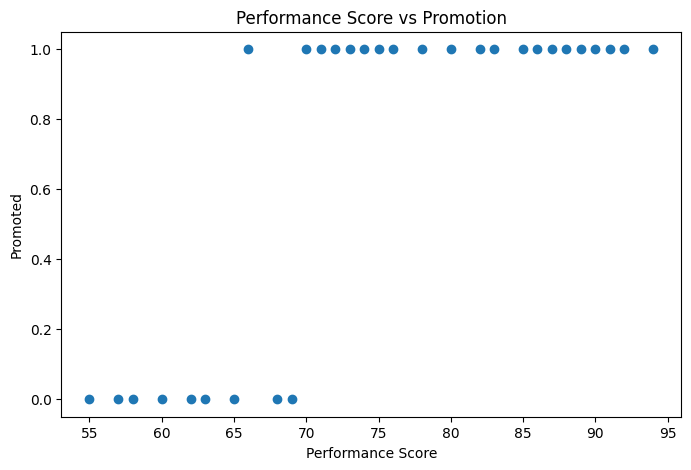

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Performance_Score"],
    df["Promoted"]
)

plt.xlabel("Performance Score")
plt.ylabel("Promoted")
plt.title("Performance Score vs Promotion")

plt.show()

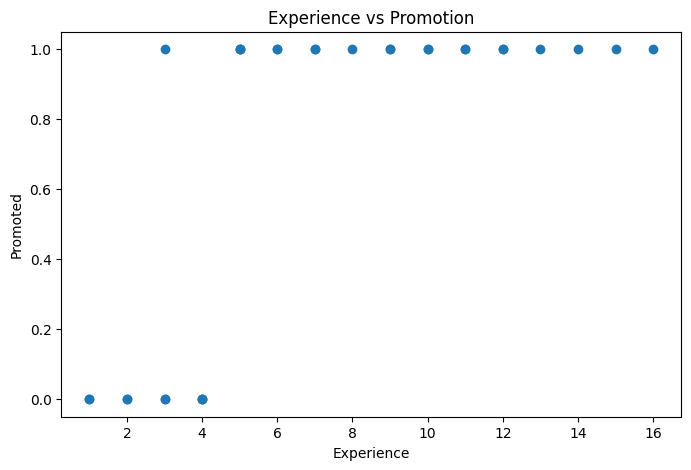

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Experience"],
    df["Promoted"]
)

plt.xlabel("Experience")
plt.ylabel("Promoted")
plt.title("Experience vs Promotion")

plt.show()

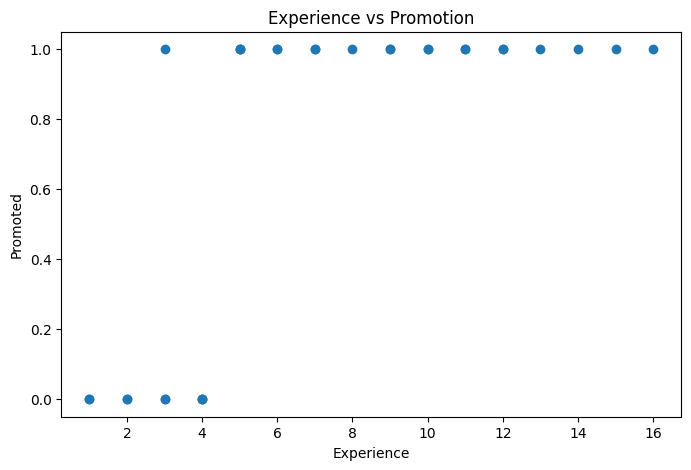

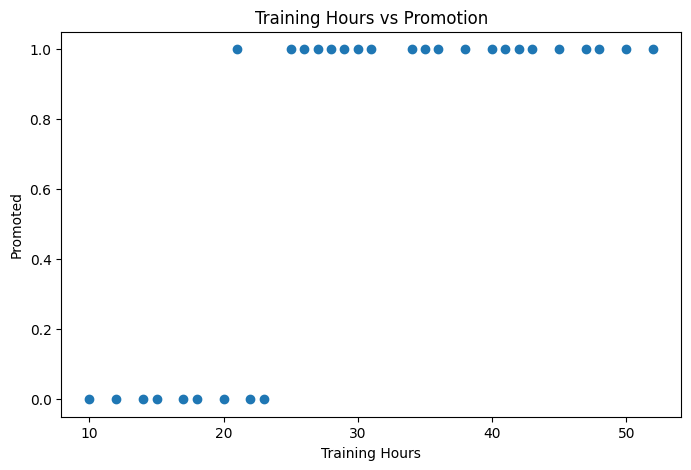

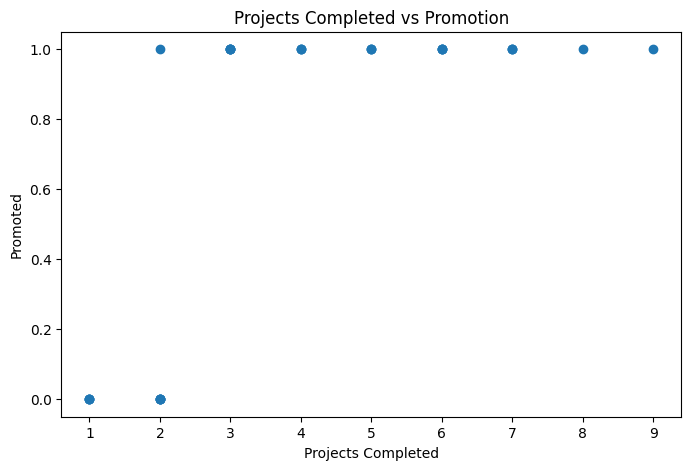

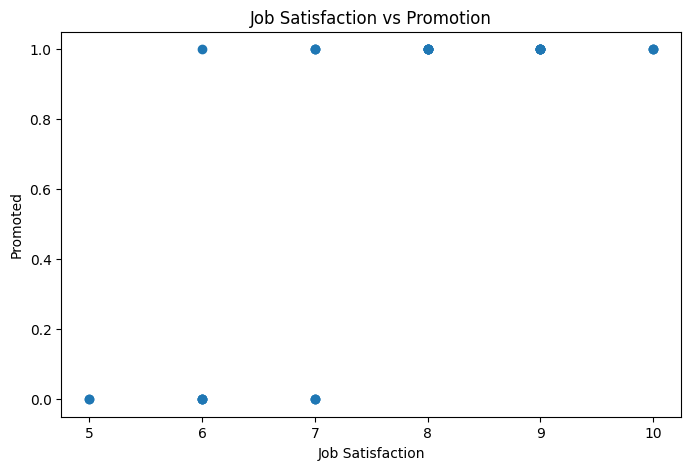

In [23]:
# Experience vs Promotion
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Experience"],
    df["Promoted"]
)

plt.xlabel("Experience")
plt.ylabel("Promoted")
plt.title("Experience vs Promotion")

plt.show()


# Training Hours vs Promotion
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Training_Hours"],
    df["Promoted"]
)

plt.xlabel("Training Hours")
plt.ylabel("Promoted")
plt.title("Training Hours vs Promotion")

plt.show()


# Projects Completed vs Promotion
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Projects_Completed"],
    df["Promoted"]
)

plt.xlabel("Projects Completed")
plt.ylabel("Promoted")
plt.title("Projects Completed vs Promotion")

plt.show()


# Job Satisfaction vs Promotion
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Job_Satisfaction"],
    df["Promoted"]
)

plt.xlabel("Job Satisfaction")
plt.ylabel("Promoted")
plt.title("Job Satisfaction vs Promotion")

plt.show()

## Select Features and Target

We will select the employee-related features as input variables and `Promoted` as the target variable.

The model will use these features to predict whether an employee will be promoted.

In [24]:
X = df[[
    "Age",
    "Experience",
    "Performance_Score",
    "Training_Hours",
    "Projects_Completed",
    "Job_Satisfaction"
]]

y = df["Promoted"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Age  Experience  Performance_Score  Training_Hours  Projects_Completed  \
0   22           1                 55              10                   1   
1   25           2                 60              15                   1   
2   28           3                 62              18                   2   
3   30           4                 65              20                   2   
4   32           5                 70              25                   3   

   Job_Satisfaction  
0                 5  
1                 6  
2                 6  
3                 7  
4                 7  

Target:
0    0
1    0
2    0
3    0
4    1
Name: Promoted, dtype: int64


## Train-Test Split

The dataset will be divided into training and testing sets.

The training data will be used to train the Decision Tree model, while the testing data will be used to evaluate how well the model performs on unseen data.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (24, 6)
Testing data: (6, 6)


## Train Decision Tree Model

We will train a Decision Tree Classification model using the training data.

The model will use the Gini impurity criterion to determine the best splits.

We will also limit the tree depth to reduce the risk of overfitting.

In [26]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


## Make Predictions

In [27]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[0 1 1 1 0 1]


## Model Evaluation

We will evaluate the performance of our Decision Tree model using accuracy, confusion matrix, precision, recall, and F1 score.

In [28]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(conf_matrix)

print("\nPrecision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 1.0

Confusion Matrix:
[[2 0]
 [0 4]]

Precision: 1.0
Recall: 1.0
F1 Score: 1.0


## Feature Importance

Feature importance shows how much each feature contributes to the Decision Tree model when making predictions.

A higher feature importance value means that the feature played a greater role in the model's decisions.

In [29]:
importance = model.feature_importances_

print("Feature Importance:")

for feature, value in zip(X.columns, importance):
    print(feature, ":", value)

Feature Importance:
Age : 0.0
Experience : 0.0
Performance_Score : 0.0
Training_Hours : 0.07563025210084034
Projects_Completed : 0.8235294117647058
Job_Satisfaction : 0.10084033613445378


## Visualize Decision Tree

We will visualize the Decision Tree to understand how the model makes promotion predictions through different decision rules and branches.

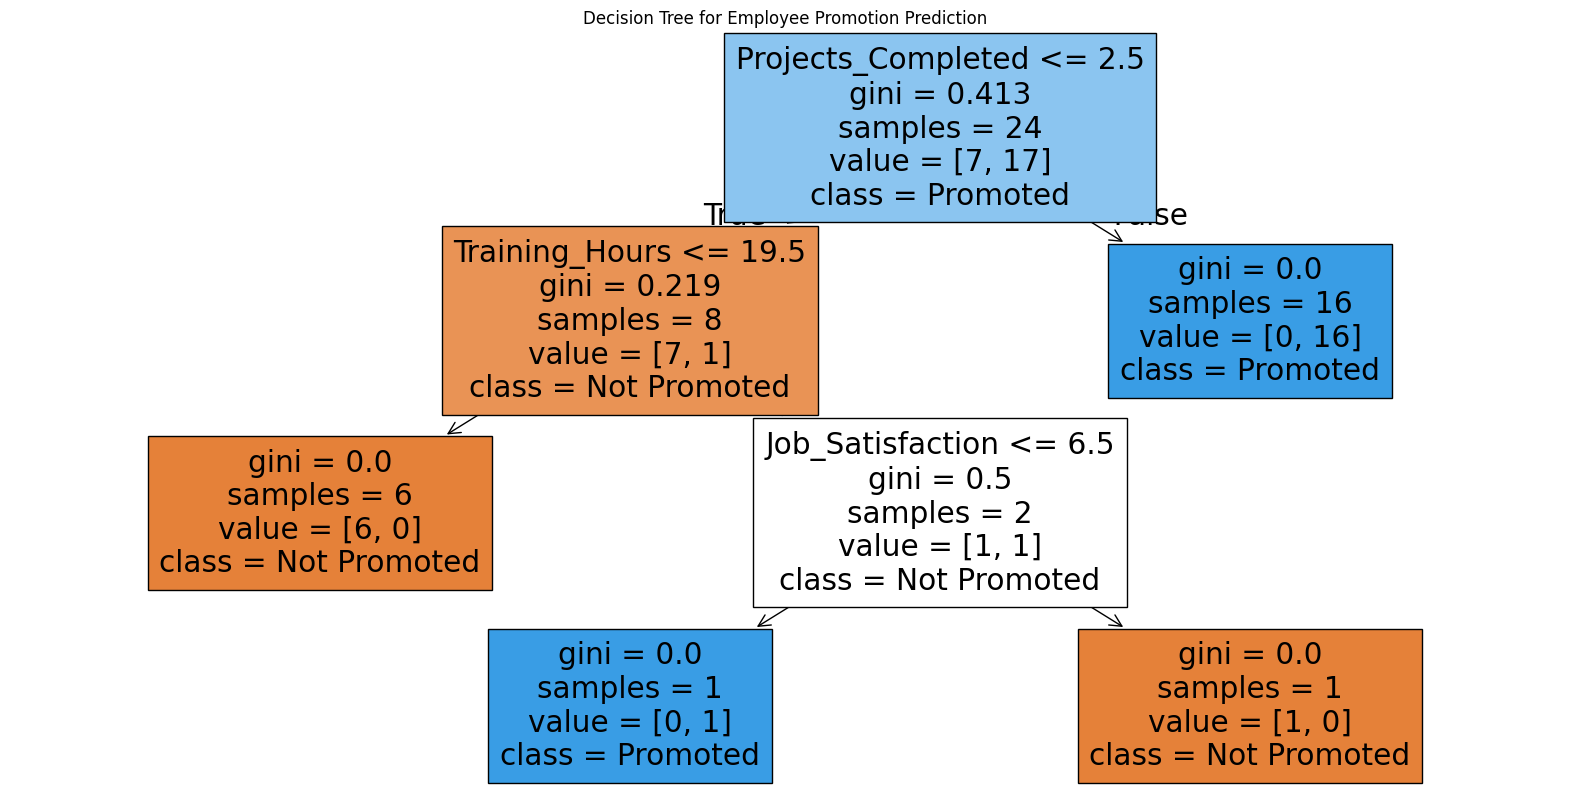

In [30]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Not Promoted", "Promoted"],
    filled=True
)

plt.title("Decision Tree for Employee Promotion Prediction")
plt.show()

## Predict a New Employee

We will use the trained Decision Tree model to predict whether a new employee will be promoted based on their age, experience, performance, training hours, completed projects, and job satisfaction.

In [31]:
new_employee = pd.DataFrame({
    "Age": [30],
    "Experience": [5],
    "Performance_Score": [75],
    "Training_Hours": [30],
    "Projects_Completed": [4],
    "Job_Satisfaction": [8]
})

prediction = model.predict(new_employee)

print("Prediction:", prediction)

if prediction[0] == 1:
    print("The employee is predicted to be Promoted.")
else:
    print("The employee is predicted to be Not Promoted.")

Prediction: [1]
The employee is predicted to be Promoted.


## Conclusion

In this project, we built a Decision Tree Classification model to predict whether an employee will be promoted.

The model was trained using employee-related features such as age, experience, performance score, training hours, projects completed, and job satisfaction.

We evaluated the model using accuracy, confusion matrix, precision, recall, and F1 score. We also analyzed feature importance and visualized the Decision Tree to understand how the model makes predictions.

Finally, we used the trained model to predict the promotion status of a new employee.